# 04 Extreme Frequency Plots for Final Period

In [1]:
%load_ext autoreload
%autoreload 2
    
import os
import sys
import pandas as pd
import xarray as xr
import numpy as np
from dask.distributed import Client
import warnings
warnings.filterwarnings('ignore')

from cdrmip_extremes import (
    utils, stats, io_disk, plotting
)
from cdrmip_extremes.configs import CDR_MODELS, PROC_DIR, FIG_DIR

In [2]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

In [4]:
base = PROC_DIR / 'CDRMIP' / 'extremes'
varname = 'tas'

ext_data = {
    name: io_disk.load_nested(base / name, f"{varname}_{name}", order=CDR_MODELS)
    for name in ['exceedances_matching_median_multimodel',
                 'branch_differences_matching_median_multimodel',
                 'agreement_matching']
}

In [5]:
exceedances = ext_data['exceedances_matching_median_multimodel']
differences = ext_data['branch_differences_matching_median_multimodel']
agreement = ext_data['agreement_matching']

Saved: /g/data/if69/sc1326/repos/cdrmip_extremes/figures/supplementary/figure_S33.jpg


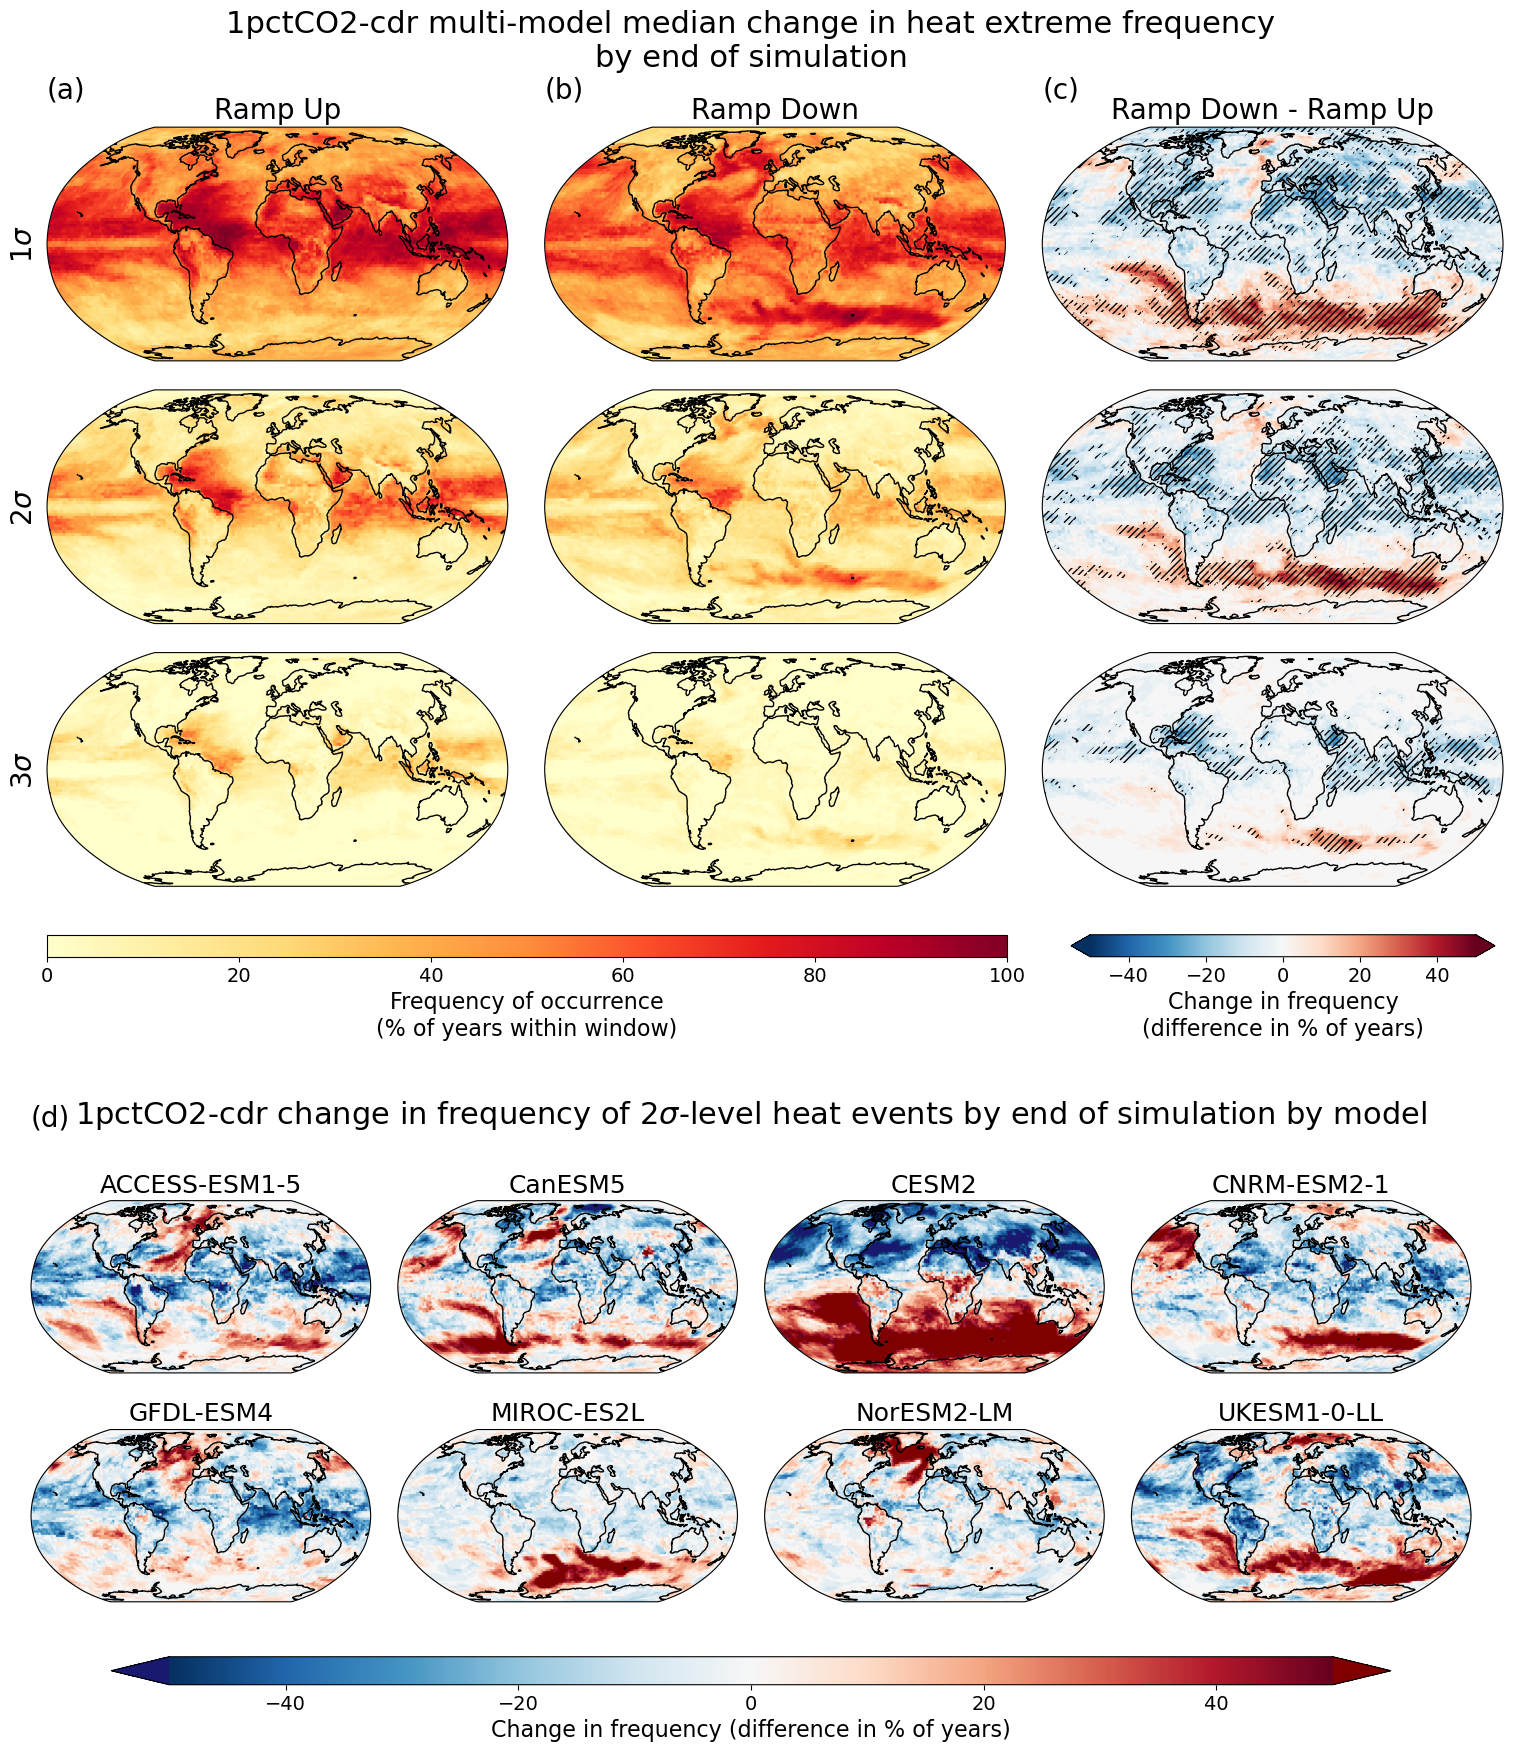

In [6]:
fig = plotting.plot_ext_freq_with_model_diffs(
    exceedances, differences, agreement,
    model='multi_model_median', expt='1pctCO2-cdr', ext_type='heat',
    gwl=None, period='final', model_name='Multi-Model Median',
    diff_threshold='sigma2',          
    diff_vmin=-50, diff_vmax=50,      
    n_cols=4, diff_label='(d)',
    suptitle='1pctCO2-cdr multi-model median change in heat extreme frequency\nby end of simulation',
    fig_dir=FIG_DIR, folder='supplementary', file_name='figure_S33.jpg',
)

Saved: /g/data/if69/sc1326/repos/cdrmip_extremes/figures/supplementary/figure_S34.jpg


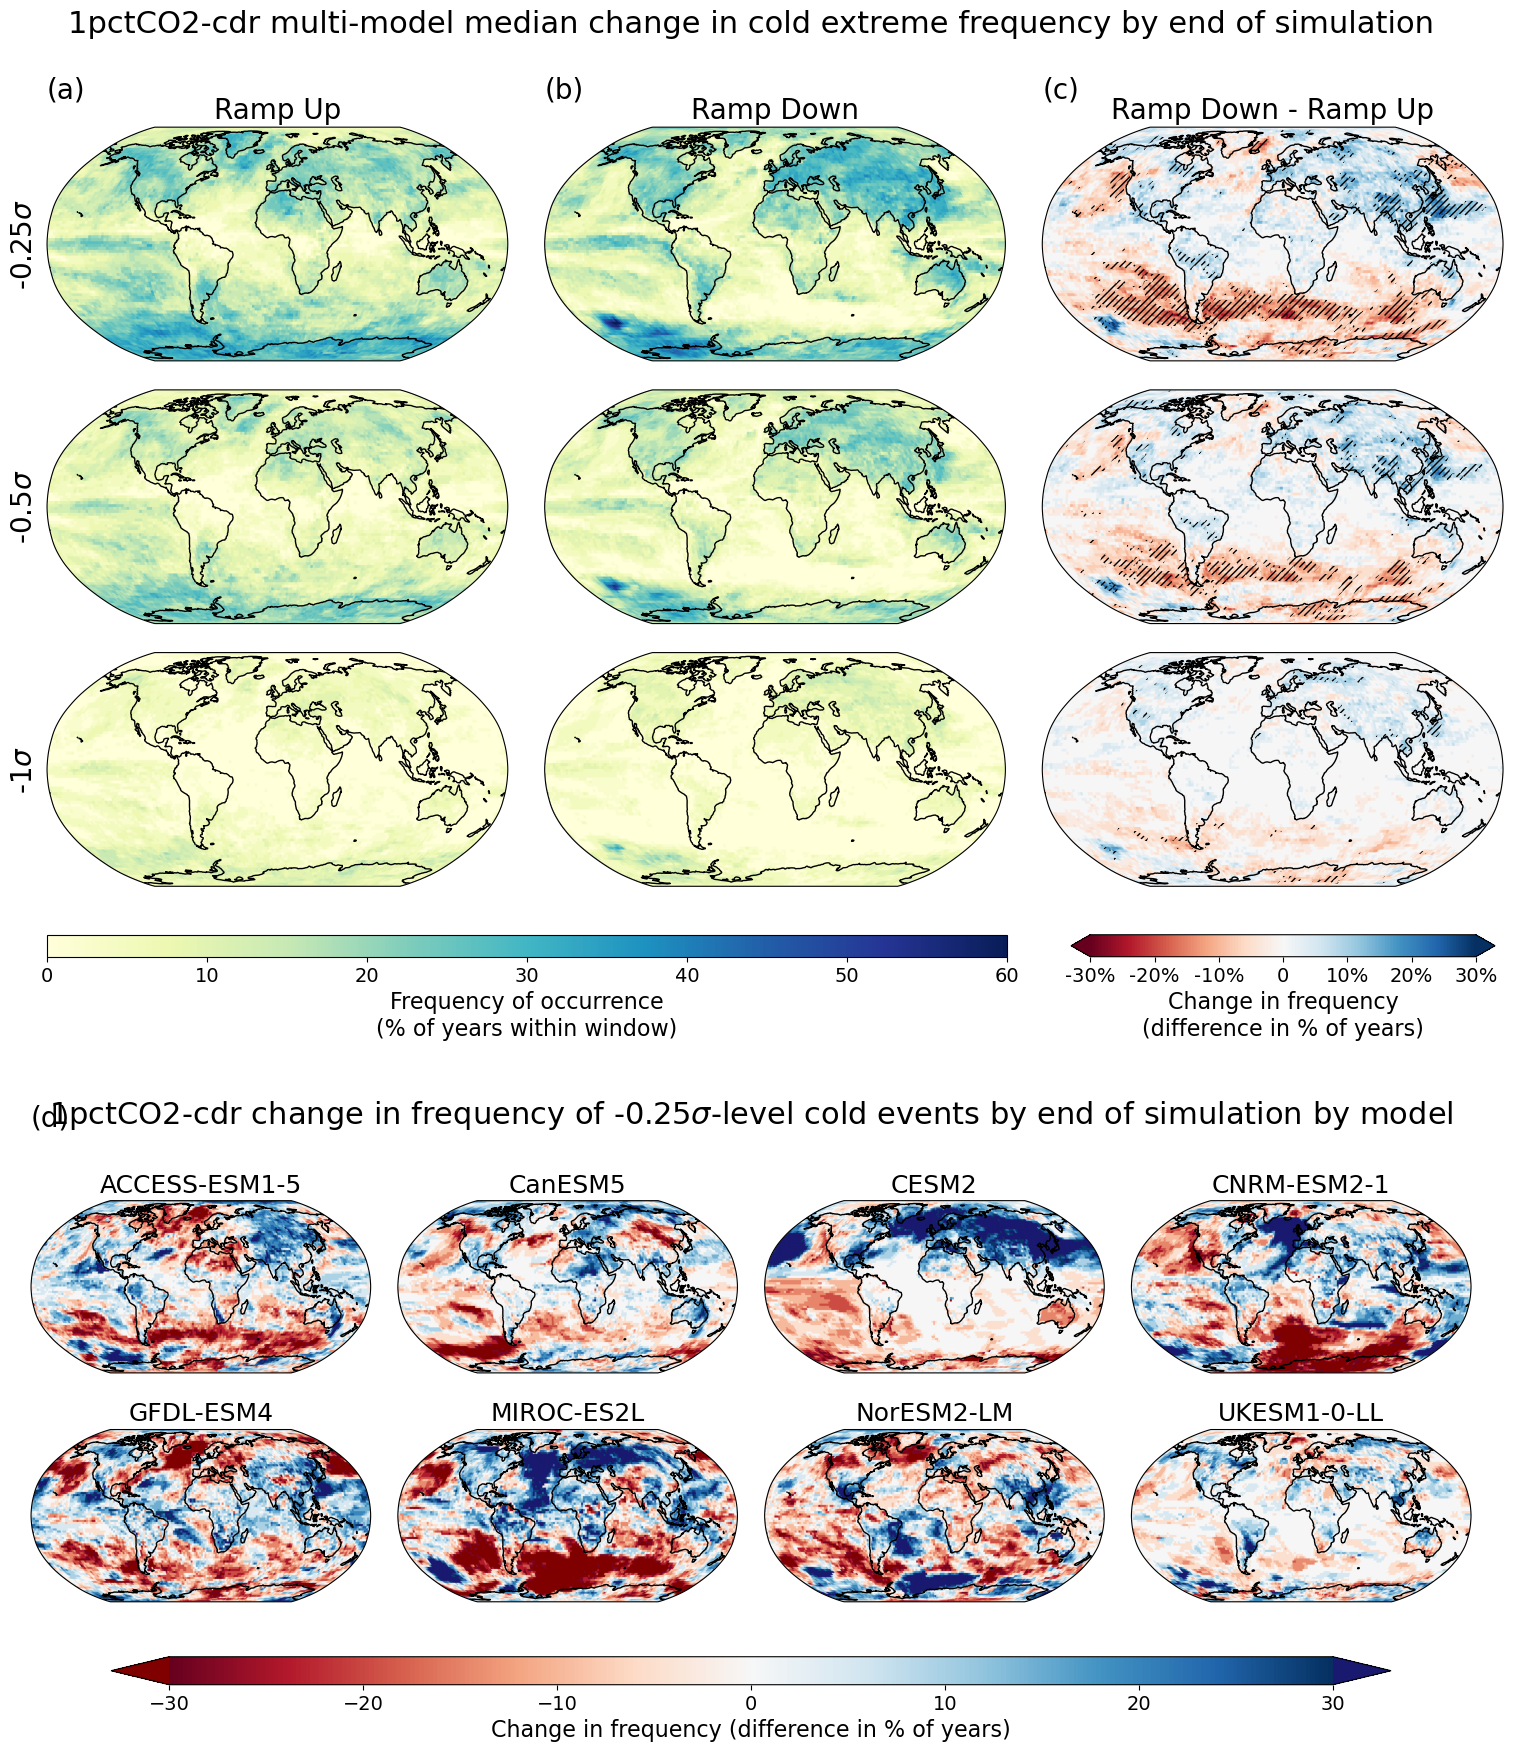

In [7]:
fig = plotting.plot_ext_freq_with_model_diffs(
    exceedances, differences, agreement,
    model='multi_model_median', expt='1pctCO2-cdr', ext_type='cold',
    gwl=None, period='final', model_name='Multi-Model Median',
    diff_threshold='sigma1',          
    diff_vmin=-30, diff_vmax=30,      
    n_cols=4, diff_label='(d)',
    suptitle='1pctCO2-cdr multi-model median change in cold extreme frequency by end of simulation',
    fig_dir=FIG_DIR, folder='supplementary', file_name='figure_S34.jpg',
)